# 02 - U-Net (patch segmentation)

- Input: 256 x 256 patches with 10 channels = 6 bands (normalized) + NDVI, NBR, NDWI + a validity channel.
- Target: the `label` band. **Missing labels (NaN) are ignored in the loss and in the metrics.**
- Loss: masked binary cross-entropy + Dice (Dice helps with the strong class imbalance, 5 % positives in 2023).
- Same train / val / test blocks as the Random Forest. Metrics are computed over every labeled pixel of the non-overlapping test patches, per year.

Use a GPU runtime (Runtime > Change runtime type > T4).

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, shutil, glob
src_dir = "/content/drive/MyDrive/PreyLang"   # the folder with copy of the tiles
os.makedirs("/content/tiles", exist_ok=True)
for f in sorted(glob.glob(f"{src_dir}/*.tif")):
    dst = f"/content/tiles/{os.path.basename(f)}"
    if not (os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(f)):
        shutil.copy(f, dst)
    print("OK " if os.path.getsize(dst) == os.path.getsize(f) else "BAD", os.path.basename(f))

Mounted at /content/drive
OK  PreyLang_Composite_2019_tile_0_0.tif
OK  PreyLang_Composite_2019_tile_0_1.tif
OK  PreyLang_Composite_2019_tile_1_0.tif
OK  PreyLang_Composite_2019_tile_1_1.tif
OK  PreyLang_Composite_2021_tile_0_0.tif
OK  PreyLang_Composite_2021_tile_0_1.tif
OK  PreyLang_Composite_2021_tile_1_0.tif
OK  PreyLang_Composite_2021_tile_1_1.tif
OK  PreyLang_Composite_2023_tile_0_0.tif
OK  PreyLang_Composite_2023_tile_0_1.tif
OK  PreyLang_Composite_2023_tile_1_0.tif
OK  PreyLang_Composite_2023_tile_1_1.tif
OK  PreyLang_Composite_2025_tile_0_0.tif
OK  PreyLang_Composite_2025_tile_0_1.tif
OK  PreyLang_Composite_2025_tile_1_0.tif
OK  PreyLang_Composite_2025_tile_1_1.tif


In [2]:
!pip -q install rasterio

In [3]:
import os, re, json, glob, time
import numpy as np, pandas as pd
import rasterio
from rasterio.windows import Window

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# ---------------- CONFIG (keep identical in all three notebooks) ----------------
TILE_DIR = "/content/tiles"                         # local copy of the 16 TIFFs (not the Drive mount)
WORK_DIR = "/content/drive/MyDrive/PreyLang_work"   # splits, stats, models and metrics are saved here
TILES    = ["0_0", "0_1", "1_0", "1_1"]
TRAIN_YEARS = [2019, 2021, 2023]                    # 2025 has no positive labels, so it is not used
BLOCK    = 1024      # spatial block size in pixels (about 10 km). A block never crosses a split.
PATCH    = 256       # U-Net patch size
SEED     = 42
BANDS    = ["B2", "B3", "B4", "B8", "B11", "B12"]
os.makedirs(WORK_DIR, exist_ok=True)
# --------------------------------------------------------------------------------

def tile_path(year, tile):
    return f"{TILE_DIR}/PreyLang_Composite_{year}_tile_{tile}.tif"

def read_window(year, tile, r0, c0, h, w):
    """Float32 array (7, h, w): B2 B3 B4 B8 B11 B12 label (NaN = missing)."""
    with rasterio.open(tile_path(year, tile)) as src:
        return src.read(window=Window(c0, r0, w, h)).astype("float32")

def add_indices(b):
    """b: (6, ...) ordered B2 B3 B4 B8 B11 B12 -> (3, ...) NDVI, NBR, NDWI."""
    eps = 1e-6
    ndvi = (b[3] - b[2]) / (b[3] + b[2] + eps)
    nbr  = (b[3] - b[5]) / (b[3] + b[5] + eps)
    ndwi = (b[1] - b[3]) / (b[1] + b[3] + eps)
    return np.stack([ndvi, nbr, ndwi])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import random
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device)

# ---- training settings ----
EPOCHS, BATCH, LR, BASE_CH, WORKERS = 20, 16, 1e-3, 32, 2
PATIENCE = 6
MIN_LAB_FRAC = 0.05     # keep patches where at least 5 % of pixels are labeled
TRAIN_STRIDE = 128      # overlapping patches for training; val/test use non-overlapping PATCH stride
POS_WEIGHT = 1.0        # raise (e.g. 2-3) if recall is poor

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

splits = json.load(open(f"{WORK_DIR}/splits.json"))
assert splits["block"] == BLOCK and splits["seed"] == SEED, "config differs from 00_data_prep"
by_split = {s: [b for b in splits["blocks"] if b["split"] == s] for s in ["train", "val", "test"]}
norm = json.load(open(f"{WORK_DIR}/norm_stats.json"))
MEAN = np.array(norm["mean"], dtype="float32"); STD = np.array(norm["std"], dtype="float32")

device: cuda


## 1. Patch index
Patches stay inside one block, so they never mix splits. The labeled area is identical across years, so it is read once (2019).

In [5]:
def build_items(block_list, years, stride):
    items = []
    for b in block_list:
        with rasterio.open(tile_path(years[0], b["tile"])) as src:
            lab = src.read(7, window=Window(b["c0"], b["r0"], b["w"], b["h"]))
        labeled = np.isfinite(lab)
        for r in range(0, b["h"] - PATCH + 1, stride):
            for c in range(0, b["w"] - PATCH + 1, stride):
                if labeled[r:r + PATCH, c:c + PATCH].mean() >= MIN_LAB_FRAC:
                    for yr in years:
                        items.append((yr, b["tile"], b["r0"] + r, b["c0"] + c))
    return items

items = {"train": build_items(by_split["train"], TRAIN_YEARS, TRAIN_STRIDE),
         "val":   build_items(by_split["val"],   TRAIN_YEARS, PATCH),
         "test":  build_items(by_split["test"],  TRAIN_YEARS, PATCH)}
print({k: len(v) for k, v in items.items()}, "patches (patch x year)")
assert all(len(v) > 0 for v in items.values()), "empty split - lower MIN_LAB_FRAC"

{'train': 2724, 'val': 138, 'test': 105} patches (patch x year)


In [6]:
class PatchDS(Dataset):
    def __init__(self, items, train=False):
        self.items, self.train, self._h = items, train, {}
    def __getstate__(self):
        d = self.__dict__.copy(); d["_h"] = {}; return d     # file handles are opened lazily per worker
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        yr, tile, r0, c0 = self.items[i]
        if (yr, tile) not in self._h:
            self._h[(yr, tile)] = rasterio.open(tile_path(yr, tile))
        a = self._h[(yr, tile)].read(window=Window(c0, r0, PATCH, PATCH)).astype("float32")
        bands, lab = a[:6], a[6].copy()
        valid = np.isfinite(bands).all(0)
        z = np.clip((bands - MEAN[:, None, None]) / STD[:, None, None], -5, 5)
        idx = np.clip(add_indices(np.nan_to_num(bands)), -1, 1)
        x = np.concatenate([z, idx, valid[None].astype("float32")], 0)
        x = np.where(valid[None], x, 0).astype("float32")
        lab[~valid] = np.nan                                   # no valid input -> no label
        x, y = torch.from_numpy(x), torch.from_numpy(lab)
        if self.train:
            if random.random() < 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() < 0.5: x, y = x.flip(-2), y.flip(-2)
            k = random.randint(0, 3)
            x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (0, 1))
        return x, y, yr

def loader(split, shuffle=False):
    return DataLoader(PatchDS(items[split], train=(split == "train")), batch_size=BATCH, shuffle=shuffle,
                      num_workers=WORKERS, pin_memory=(device.type == "cuda"), persistent_workers=WORKERS > 0)

train_dl, val_dl, test_dl = loader("train", True), loader("val"), loader("test")
x0, y0, _ = next(iter(train_dl))
print("batch:", x0.shape, y0.shape, "| labeled share in batch:", float(torch.isfinite(y0).float().mean()))

batch: torch.Size([16, 10, 256, 256]) torch.Size([16, 256, 256]) | labeled share in batch: 0.3935222625732422


## 2. Model and loss

In [7]:
def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    """Classic U-Net: 4 down steps, 4 up steps with skip connections, 1 output channel (logit)."""
    def __init__(self, cin, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([conv_block(cin, ch[0])] + [conv_block(ch[i], ch[i + 1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([conv_block(ch[i] * 2, ch[i]) for i in range(4)])
        self.out = nn.Conv2d(ch[0], 1, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips[-1]
        for i in reversed(range(4)):
            x = self.up[i](x)
            x = self.dec[i](torch.cat([x, skips[i]], 1))
        return self.out(x)

def masked_loss(logits, y):
    """BCE + Dice computed only where the label is finite."""
    m = torch.isfinite(y)
    if m.sum() == 0:
        return logits.sum() * 0
    yy = torch.where(m, y, torch.zeros_like(y))
    pw = torch.tensor(POS_WEIGHT, device=logits.device)
    bce = F.binary_cross_entropy_with_logits(logits[m], yy[m], pos_weight=pw)
    p = torch.sigmoid(logits) * m
    dice = 1 - (2 * (p * yy).sum() + 1) / (p.sum() + (yy * m).sum() + 1)
    return bce + dice

model = UNet(cin=10, base=BASE_CH).to(device)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

7.8M parameters


## 3. Evaluation helper
Counts TP/FP/FN/TN over labeled pixels only, for many thresholds at once, per year.

In [8]:
@torch.no_grad()
def evaluate(model, dl, thresholds):
    model.eval()
    th = torch.tensor(thresholds, device=device, dtype=torch.float32).view(-1, 1, 1)
    counts = {}
    for x, y, yr in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            p = torch.sigmoid(model(x)[:, 0].float())
        for i in range(x.shape[0]):
            m = torch.isfinite(y[i]); t = (torch.nan_to_num(y[i]) == 1) & m
            pred = (p[i][None] >= th) & m[None]
            tp = (pred & t[None]).sum((1, 2)); fp = (pred & ~t[None]).sum((1, 2))
            fn = ((~pred) & t[None] & m[None]).sum((1, 2)); tn = ((~pred) & ~t[None] & m[None]).sum((1, 2))
            c = torch.stack([tp, fp, fn, tn], 1).cpu().numpy().astype("int64")
            counts[int(yr[i])] = counts.get(int(yr[i]), 0) + c
    return counts                                              # year -> (T, 4)

def scores(c):                                                 # c: (4,) tp fp fn tn
    tp, fp, fn, tn = [int(v) for v in c]
    return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1),
                iou=tp / max(tp + fp + fn, 1), accuracy=(tp + tn) / max(tp + fp + fn + tn, 1),
                n=tp + fp + fn + tn, positives=tp + fn, prevalence=(tp + fn) / max(tp + fp + fn + tn, 1))

def table(counts, ti):
    rows = {str(y): scores(counts[y][ti]) for y in sorted(counts)}
    rows["all"] = scores(sum(counts[y][ti] for y in counts))
    return pd.DataFrame(rows).T.round(3)

## 4. Train
Keeps the checkpoint with the best pooled val F1 and stops after `PATIENCE` epochs without improvement.

In [9]:
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
best_f1, best_ep, history = -1, -1, []

for ep in range(EPOCHS):
    model.train(); t0 = time.time(); tot, n = 0.0, 0
    for x, y, _ in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            logits = model(x)[:, 0]
        loss = masked_loss(logits.float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += float(loss) * x.shape[0]; n += x.shape[0]
    sched.step()
    vt = table(evaluate(model, val_dl, [0.5]), 0).loc["all"]
    history.append(dict(epoch=ep + 1, train_loss=tot / n, val_f1=vt.f1, val_iou=vt.iou,
                        val_precision=vt.precision, val_recall=vt.recall))
    print(f"ep {ep+1:02d}  loss {tot/n:.4f}  val F1 {vt.f1:.3f}  IoU {vt.iou:.3f}  P {vt.precision:.3f}  R {vt.recall:.3f}  ({time.time()-t0:.0f}s)")
    if vt.f1 > best_f1:
        best_f1, best_ep = vt.f1, ep
        torch.save(model.state_dict(), f"{WORK_DIR}/unet_best.pt")
    elif ep - best_ep >= PATIENCE:
        print("early stop"); break
print(f"best val F1 {best_f1:.3f} at epoch {best_ep+1}")

/tmp/ipykernel_383/512775097.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_383/512775097.py:15: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss) * x.shape[0]; n += x.shape[0]


ep 01  loss 0.8103  val F1 0.728  IoU 0.573  P 0.687  R 0.775  (86s)
ep 02  loss 0.6857  val F1 0.723  IoU 0.566  P 0.694  R 0.755  (73s)
ep 03  loss 0.6651  val F1 0.736  IoU 0.582  P 0.680  R 0.801  (75s)
ep 04  loss 0.6433  val F1 0.737  IoU 0.584  P 0.689  R 0.793  (76s)
ep 05  loss 0.6350  val F1 0.730  IoU 0.575  P 0.705  R 0.758  (75s)
ep 06  loss 0.6389  val F1 0.750  IoU 0.600  P 0.723  R 0.779  (73s)
ep 07  loss 0.6177  val F1 0.743  IoU 0.591  P 0.692  R 0.801  (74s)
ep 08  loss 0.6110  val F1 0.748  IoU 0.597  P 0.715  R 0.784  (74s)
ep 09  loss 0.6050  val F1 0.745  IoU 0.594  P 0.770  R 0.721  (72s)
ep 10  loss 0.5986  val F1 0.732  IoU 0.577  P 0.771  R 0.696  (73s)
ep 11  loss 0.5956  val F1 0.754  IoU 0.605  P 0.771  R 0.738  (74s)
ep 12  loss 0.5862  val F1 0.743  IoU 0.591  P 0.716  R 0.772  (75s)
ep 13  loss 0.5915  val F1 0.743  IoU 0.591  P 0.754  R 0.732  (71s)
ep 14  loss 0.5865  val F1 0.752  IoU 0.603  P 0.729  R 0.777  (74s)
ep 15  loss 0.5732  val F1 0.752  

## 5. Threshold on val, final test metrics, save

In [10]:
model.load_state_dict(torch.load(f"{WORK_DIR}/unet_best.pt", map_location=device))
grid = np.linspace(0.05, 0.95, 19)
cv = evaluate(model, val_dl, grid)
val_f1 = [scores(sum(cv[y][i] for y in cv))["f1"] for i in range(len(grid))]
thr = float(grid[int(np.argmax(val_f1))])
print(f"best threshold on val: {thr:.2f} (val F1 {max(val_f1):.3f})")

ct = evaluate(model, test_dl, np.array([0.5, thr]))
print("\nTEST @ 0.50"); res_050 = table(ct, 0); print(res_050)
print(f"\nTEST @ {thr:.2f} (tuned on val)"); res_tuned = table(ct, 1); print(res_tuned)

json.dump({"threshold": thr, "test_at_0.5": res_050.to_dict("index"), "test_tuned": res_tuned.to_dict("index"),
           "history": history, "settings": dict(epochs=EPOCHS, batch=BATCH, lr=LR, base_ch=BASE_CH,
           min_lab_frac=MIN_LAB_FRAC, train_stride=TRAIN_STRIDE, pos_weight=POS_WEIGHT)},
          open(f"{WORK_DIR}/unet_metrics.json", "w"), indent=1)
print("saved unet_best.pt and unet_metrics.json")

best threshold on val: 0.40 (val F1 0.755)

TEST @ 0.50
      precision  recall     f1    iou  accuracy          n  positives  \
2019      0.783   0.520  0.625  0.454     0.907  1513743.0   224633.0   
2021      0.759   0.510  0.610  0.439     0.938  1513743.0   144407.0   
2023      0.404   0.309  0.350  0.212     0.955  1513743.0    58950.0   
all       0.717   0.487  0.580  0.409     0.934  4541229.0   427990.0   

      prevalence  
2019       0.148  
2021       0.095  
2023       0.039  
all        0.094  

TEST @ 0.40 (tuned on val)
      precision  recall     f1    iou  accuracy          n  positives  \
2019      0.770   0.536  0.632  0.462     0.907  1513743.0   224633.0   
2021      0.739   0.525  0.614  0.443     0.937  1513743.0   144407.0   
2023      0.393   0.325  0.356  0.216     0.954  1513743.0    58950.0   
all       0.700   0.503  0.585  0.414     0.933  4541229.0   427990.0   

      prevalence  
2019       0.148  
2021       0.095  
2023       0.039  
all        0.

## 6. Look at a few test predictions
Red/green/blue = B4/B3/B2 (brightened). Gray in the label panel = not labeled.

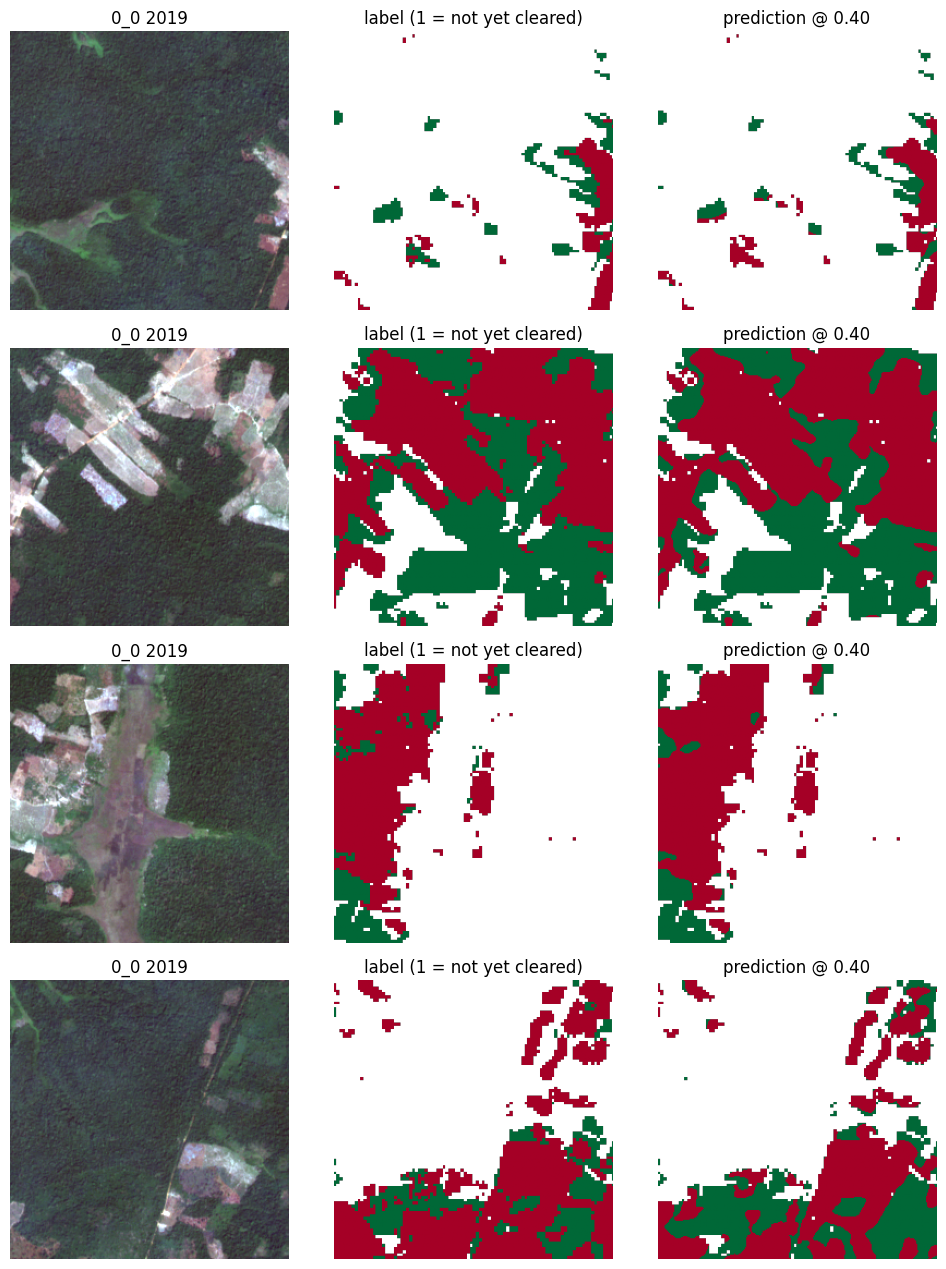

In [11]:
import matplotlib.pyplot as plt
ds = PatchDS(items["test"])
pick = [i for i, it in enumerate(items["test"]) if it[0] == TRAIN_YEARS[0]][:4]
fig, ax = plt.subplots(len(pick), 3, figsize=(10, 3.2 * len(pick)), squeeze=False)
model.eval()
for r, i in enumerate(pick):
    x, y, yr = ds[i]
    with torch.no_grad():
        p = torch.sigmoid(model(x[None].to(device).float())[0, 0]).cpu().numpy()
    rgb = x[[2, 1, 0]].numpy().transpose(1, 2, 0); rgb = np.clip((rgb + 2) / 5, 0, 1)
    lab = np.ma.masked_invalid(y.numpy()); pr = np.ma.masked_where(~np.isfinite(y.numpy()), (p >= thr).astype(float))
    ax[r, 0].imshow(rgb); ax[r, 0].set_title(f"{items['test'][i][1]} {yr}")
    ax[r, 1].imshow(lab, vmin=0, vmax=1, cmap="RdYlGn"); ax[r, 1].set_title("label (1 = not yet cleared)")
    ax[r, 2].imshow(pr, vmin=0, vmax=1, cmap="RdYlGn"); ax[r, 2].set_title(f"prediction @ {thr:.2f}")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/unet_test_examples.png", dpi=120); plt.show()